# Proyek Analisis Data: E-Commerce Public Dataset (Olist)
- **Nama:** Zacky Bayu Prasongko
- **Email:** ds009b6y1994@student.devacademy.id
- **ID Dicoding:** DS009B6Y1994

## Menentukan Pertanyaan Bisnis

Dataset yang digunakan adalah **E-Commerce Public Dataset** milik Olist, yaitu data transaksi marketplace di Brasil. Seluruh pertanyaan dibatasi pada periode **Januari 2017 sampai Agustus 2018** karena pada periode tersebut data bulanan tersedia secara berkesinambungan, sedangkan data 2016 tidak lengkap dan data September sampai Oktober 2018 terpotong (proses penentuan periode dijelaskan pada tahap *Assessing Data*). Nilai uang dinyatakan dalam Real Brasil (BRL, simbol R$).

- **Pertanyaan 1:** Kategori produk apa saja yang menghasilkan total pendapatan (harga barang, tanpa ongkos kirim) tertinggi, dan berapa persen kontribusi 10 kategori teratas terhadap total pendapatan pesanan berstatus *delivered* selama Januari 2017 sampai Agustus 2018?
- **Pertanyaan 2:** Bagaimana tren jumlah pesanan dan total pendapatan bulanan beserta pertumbuhan *Month-over-Month* (MoM) selama Januari 2017 sampai Agustus 2018, dan pada bulan apa terjadi kenaikan pendapatan terbesar (dalam nilai R$) dibandingkan bulan sebelumnya?
- **Pertanyaan 3:** Berapa selisih rata-rata skor ulasan antara pesanan yang tiba tepat waktu dan pesanan yang terlambat, serta negara bagian mana yang memiliki persentase keterlambatan tertinggi, selama Januari 2017 sampai Agustus 2018?

## Import Semua Packages/Library yang Digunakan

In [ ]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")

# Pengaturan tampilan: palet hitam-putih (grayscale) dan font serif
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "figure.dpi": 110,
})
sns.set_style("whitegrid", {"grid.color": "#DDDDDD", "axes.spines.top": False, "axes.spines.right": False})

DARK, MID, LIGHT = "#1A1A1A", "#808080", "#C8C8C8"
pd.options.display.float_format = "{:,.2f}".format
pd.set_option("display.max_columns", 30)

## Data Wrangling

### Gathering Data

Sebanyak sembilan berkas CSV dimuat ke dalam DataFrame. Kolom kode pos dibaca sebagai teks (*string*) agar angka nol di depan kode pos tidak hilang, sehingga proses penggabungan dengan data geolokasi tetap akurat.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
DATA_PATH = r"/content/drive/MyDrive/DICODING ASAH/Submission: Analisis Data/Dataset/E-commerce-public-dataset/"

#### Load df customers

In [ ]:
customers = pd.read_csv(DATA_PATH + "customers_dataset.csv", dtype={"customer_zip_code_prefix": str})
print("Dimensi:", customers.shape)
customers.head()

Dimensi: (99441, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


#### Load df orders

In [ ]:
orders = pd.read_csv(DATA_PATH + "orders_dataset.csv")
print("Dimensi:", orders.shape)
orders.head()

Dimensi: (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


#### Load df order_items

In [ ]:
order_items = pd.read_csv(DATA_PATH + "order_items_dataset.csv")
print("Dimensi:", order_items.shape)
order_items.head()

Dimensi: (112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


#### Load df order_payments

In [ ]:
order_payments = pd.read_csv(DATA_PATH + "order_payments_dataset.csv")
print("Dimensi:", order_payments.shape)
order_payments.head()

Dimensi: (103886, 5)


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


#### Load df order_reviews

In [ ]:
order_reviews = pd.read_csv(DATA_PATH + "order_reviews_dataset.csv")
print("Dimensi:", order_reviews.shape)
order_reviews.head()

Dimensi: (99224, 7)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


#### Load df products dan terjemahan kategori

In [ ]:
products = pd.read_csv(DATA_PATH + "products_dataset.csv")
category_translation = pd.read_csv(DATA_PATH + "product_category_name_translation.csv", encoding="utf-8-sig")
print("Dimensi products:", products.shape)
print("Dimensi category_translation:", category_translation.shape)
products.head()

Dimensi products: (32951, 9)
Dimensi category_translation: (71, 2)


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.00,287.00,1.00,225.00,16.00,10.00,14.00
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.00,276.00,1.00,"1,000.00",30.00,18.00,20.00
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.00,250.00,1.00,154.00,18.00,9.00,15.00
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.00,261.00,1.00,371.00,26.00,4.00,26.00
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.00,402.00,4.00,625.00,20.00,17.00,13.00


#### Load df sellers dan geolocation

In [ ]:
sellers = pd.read_csv(DATA_PATH + "sellers_dataset.csv", dtype={"seller_zip_code_prefix": str})
geolocation = pd.read_csv(DATA_PATH + "geolocation_dataset.csv", dtype={"geolocation_zip_code_prefix": str})
print("Dimensi sellers:", sellers.shape)
print("Dimensi geolocation:", geolocation.shape)
geolocation.head()

Dimensi sellers: (3095, 4)
Dimensi geolocation: (1000163, 5)


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,01037,-23.55,-46.64,sao paulo,SP
1,01046,-23.55,-46.64,sao paulo,SP
2,01046,-23.55,-46.64,sao paulo,SP
3,01041,-23.54,-46.64,sao paulo,SP
4,01035,-23.54,-46.64,sao paulo,SP


**Insight:**
- Terdapat sembilan tabel yang saling berelasi melalui kunci `order_id`, `customer_id`, `product_id`, `seller_id`, dan kode pos.
- Tabel `geolocation` merupakan tabel terbesar (1.000.163 baris), sedangkan tabel `orders` dan `customers` masing-masing memuat 99.441 baris.
- Satu pelanggan dapat memiliki beberapa `customer_id` (satu per pesanan), sehingga analisis pelanggan harus menggunakan `customer_unique_id`.

### Assessing Data

#### Identifying missing value problem

In [ ]:
# Mengumpulkan seluruh tabel dalam satu dictionary agar dapat diperiksa dengan satu perulangan
datasets = {
    "customers": customers, "orders": orders, "order_items": order_items,
    "order_payments": order_payments, "order_reviews": order_reviews,
    "products": products, "category_translation": category_translation,
    "sellers": sellers, "geolocation": geolocation,
}

rows = []
for name, df in datasets.items():
    mv = df.isna().sum()
    # Hanya kolom yang memiliki missing value (jumlah > 0) yang dicatat pada ringkasan
    for col, val in mv[mv > 0].items():
        rows.append({"tabel": name, "kolom": col, "jumlah_missing": val,
                     # Persentase dihitung terhadap jumlah baris pada tabel yang bersangkutan
                     "persentase": round(val / len(df) * 100, 2)})
pd.DataFrame(rows)

,tabel,kolom,jumlah_missing,persentase
0,orders,order_approved_at,160,0.16
1,orders,order_delivered_carrier_date,1783,1.79
2,orders,order_delivered_customer_date,2965,2.98
3,order_reviews,review_comment_title,87656,88.34
4,order_reviews,review_comment_message,58247,58.70
5,products,product_category_name,610,1.85
6,products,product_name_lenght,610,1.85
7,products,product_description_lenght,610,1.85
8,products,product_photos_qty,610,1.85
9,products,product_weight_g,2,0.01


#### Identifying duplicate data problem

In [ ]:
# Duplikat penuh: baris dianggap duplikat jika seluruh kolomnya identik
dup_summary = pd.DataFrame({
    "tabel": list(datasets.keys()),
    "jumlah_baris": [len(df) for df in datasets.values()],
    "baris_duplikat": [df.duplicated().sum() for df in datasets.values()],
})
display(dup_summary)

# Duplikasi pada level kunci: satu pesanan seharusnya hanya memiliki satu ulasan
# duplicated() tanpa keep=False hanya menghitung kemunculan kedua dan seterusnya (baris berlebih)
print("Jumlah baris ulasan berlebih (order_id yang sudah muncul sebelumnya):",
      order_reviews["order_id"].duplicated().sum())

# keep=False menandai seluruh kemunculan sehingga ulasan ganda pada pesanan yang sama dapat dibandingkan
display(order_reviews[order_reviews["order_id"].duplicated(keep=False)]
        .sort_values("order_id")[["order_id", "review_score", "review_answer_timestamp"]].head(6))

,tabel,jumlah_baris,baris_duplikat
0,customers,99441,0
1,orders,99441,0
2,order_items,112650,0
3,order_payments,103886,0
4,order_reviews,99224,0
5,products,32951,0
6,category_translation,71,0
7,sellers,3095,0
8,geolocation,1000163,261831


Jumlah baris ulasan berlebih (order_id yang sudah muncul sebelumnya): 551


,order_id,review_score,review_answer_timestamp
25612,0035246a40f520710769010f752e7507,5,2017-08-30 01:59:12
22423,0035246a40f520710769010f752e7507,5,2017-08-29 21:45:57
22779,013056cfe49763c6f66bda03396c5ee3,5,2018-02-23 12:12:30
68633,013056cfe49763c6f66bda03396c5ee3,4,2018-03-05 17:02:00
854,0176a6846bcb3b0d3aa3116a9a768597,5,2018-01-02 10:54:06
83224,0176a6846bcb3b0d3aa3116a9a768597,5,2018-01-02 10:54:47


#### Identifying inaccurate value dan inconsistent value problem

In [ ]:
# 1. Tipe data kolom tanggal pada tabel orders
print("Tipe data kolom orders:")
print(orders.dtypes)

# 2. Kategori produk pada tabel products yang tidak memiliki padanan terjemahan
missing_translation = set(products["product_category_name"].dropna()) - set(category_translation["product_category_name"])
print("\nKategori tanpa terjemahan:", missing_translation)

# 3. Penulisan nama kolom yang tidak konsisten (typo "lenght")
print("\nKolom bertypo:", [c for c in products.columns if "lenght" in c])

Tipe data kolom orders:
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

Kategori tanpa terjemahan: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}

Kolom bertypo: ['product_name_lenght', 'product_description_lenght']


#### Identifying invalid value problem

In [ ]:
# Salinan dipakai agar tabel orders asli tidak berubah; konversi tipe data resmi dilakukan pada tahap Cleaning
orders_chk = orders.copy()
for c in ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]:
    orders_chk[c] = pd.to_datetime(orders_chk[c])

# Konsistensi logika antara status pesanan dan tanggal
print("Pesanan berstatus delivered tanpa tanggal tiba:",
      ((orders_chk["order_status"] == "delivered") & orders_chk["order_delivered_customer_date"].isna()).sum())
print("Pesanan non-delivered yang memiliki tanggal tiba:",
      ((orders_chk["order_status"] != "delivered") & orders_chk["order_delivered_customer_date"].notna()).sum())

# Perbandingan dengan tanggal kosong (NaT) bernilai False, sehingga pesanan tanpa tanggal tiba tidak ikut dihitung
print("Pesanan tiba sebelum tanggal pembelian:",
      (orders_chk["order_delivered_customer_date"] < orders_chk["order_purchase_timestamp"]).sum())

# Pembayaran yang sah seharusnya bernilai positif, minimal satu kali cicilan, dan bertipe terdefinisi
print("\nPembayaran dengan nilai 0:", (order_payments["payment_value"] == 0).sum())
print("Pembayaran dengan cicilan 0:", (order_payments["payment_installments"] == 0).sum())
print("Pembayaran bertipe not_defined:", (order_payments["payment_type"] == "not_defined").sum())

# Batas koordinat wilayah daratan Brasil (perkiraan berupa kotak, bukan garis batas negara),
# sehingga titik di negara tetangga yang masuk kotak ini tidak terdeteksi (hasil adalah batas bawah).
# Titik dianggap di luar Brasil jika lintang ATAU bujurnya berada di luar rentang.
out_brazil = ~geolocation["geolocation_lat"].between(-33.75, 5.28) | ~geolocation["geolocation_lng"].between(-73.99, -34.79)
print("\nTitik geolokasi di luar wilayah Brasil:", out_brazil.sum())

Pesanan berstatus delivered tanpa tanggal tiba: 8
Pesanan non-delivered yang memiliki tanggal tiba: 6
Pesanan tiba sebelum tanggal pembelian: 0

Pembayaran dengan nilai 0: 9
Pembayaran dengan cicilan 0: 2
Pembayaran bertipe not_defined: 3

Titik geolokasi di luar wilayah Brasil: 42


#### Identifying outlier dan incomplete period problem

In [ ]:
# Fungsi menghitung jumlah outlier dengan aturan IQR (Tukey):
# nilai di luar rentang [Q1 - 1,5 x IQR, Q3 + 1,5 x IQR] ditandai sebagai outlier.
# Aturan ini heuristik: nilai yang ditandai belum tentu salah (misalnya barang mahal yang sah).
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

# Lama pengiriman hanya bermakna untuk pesanan yang sudah tiba (status delivered)
delivered_tmp = orders_chk[orders_chk["order_status"] == "delivered"].copy()
# .dt.days memotong selisih ke hari bulat (tidak dibulatkan)
delivery_days = (delivered_tmp["order_delivered_customer_date"] - delivered_tmp["order_purchase_timestamp"]).dt.days

# Statistik price dan freight_value dihitung pada seluruh data sebelum filter periode
outlier_summary = pd.DataFrame({
    "variabel": ["price", "freight_value", "lama_pengiriman_hari"],
    "maksimum": [order_items["price"].max(), order_items["freight_value"].max(), delivery_days.max()],
    "persentil_99": [order_items["price"].quantile(.99), order_items["freight_value"].quantile(.99), delivery_days.quantile(.99)],
    "jumlah_outlier_IQR": [iqr_outliers(order_items["price"]), iqr_outliers(order_items["freight_value"]), iqr_outliers(delivery_days.dropna())],
})
display(outlier_summary)

# Kelengkapan periode: jumlah pesanan per bulan (seluruh status pesanan)
monthly_count = orders_chk.groupby(orders_chk["order_purchase_timestamp"].dt.to_period("M")).size().rename("jumlah_pesanan")
# reindex menampilkan bulan tanpa data sebagai 0 (groupby biasa menghilangkan bulan kosong)
monthly_count = monthly_count.reindex(
    pd.period_range(monthly_count.index.min(), monthly_count.index.max(), freq="M"), fill_value=0)

# Ambang 1.000 pesanan adalah batas praktis untuk menandai bulan yang datanya sangat sedikit
print("Bulan dengan jumlah pesanan kurang dari 1.000:")
print(monthly_count[monthly_count < 1000])
print("\nRentang tanggal pembelian:", orders_chk["order_purchase_timestamp"].min(), "sampai", orders_chk["order_purchase_timestamp"].max())

,variabel,maksimum,persentil_99,jumlah_outlier_IQR
0,price,"6,735.00",890.00,8427
1,freight_value,409.68,84.52,12134
2,lama_pengiriman_hari,209.00,46.00,5022


Bulan dengan jumlah pesanan kurang dari 1.000:
2016-09      4
2016-10    324
2016-11      0
2016-12      1
2017-01    800
2018-09     16
2018-10      4
Freq: M, Name: jumlah_pesanan, dtype: int64

Rentang tanggal pembelian: 2016-09-04 21:15:19 sampai 2018-10-17 17:30:18


**Steps to Take:**
- **Missing value:** pesanan *delivered* tanpa tanggal tiba dikeluarkan karena tidak dapat dihitung ketepatan pengirimannya; kategori produk yang kosong diisi `unknown`; kolom komentar ulasan yang kosong tidak digunakan sehingga dibiarkan.
- **Duplicate data:** ulasan ganda per pesanan dikurangi dengan mempertahankan ulasan terbaru; baris duplikat pada `geolocation` dihapus.
- **Inaccurate value:** kolom tanggal pada `orders` dikonversi ke tipe `datetime`.
- **Inconsistent value:** nama kategori diterjemahkan ke Bahasa Inggris, dua kategori tanpa terjemahan ditambahkan secara manual, dan kolom bertypo diperbaiki namanya.
- **Invalid value:** pembayaran bernilai 0 atau bertipe `not_defined` dikeluarkan, dan titik geolokasi di luar wilayah Brasil dihapus.
- **Outlier:** nilai `price` dan `freight_value` yang tinggi serta lama pengiriman yang panjang merupakan nilai yang masuk akal secara bisnis (barang mahal, wilayah terpencil), sehingga **tidak dihapus**.
- **Incomplete period:** analisis dibatasi pada Januari 2017 sampai Agustus 2018. Data 2016 tidak berkesinambungan (tidak ada pesanan pada November 2016) dan data September sampai Oktober 2018 terpotong. Januari 2017 tetap diikutkan sebagai bulan pertama yang berkesinambungan, tetapi nilainya relatif rendah karena marketplace mungkin masih pada fase awal pertumbuhan sehingga pertumbuhan MoM Februari dan Maret 2017 perlu ditafsirkan dengan hati-hati.

**Insight:**
- **Missing value:** kolom `order_delivered_customer_date` kosong pada 2.965 pesanan (2,98%), kategori produk kosong pada 610 produk (1,85%), dan komentar ulasan kosong pada 58,70% (pesan) serta 88,34% (judul) ulasan.
- **Duplicate data:** hanya tabel `geolocation` yang memiliki baris duplikat penuh (261.831 baris, sekitar 26% dari total), sedangkan tabel `order_reviews` memiliki 551 `order_id` yang muncul lebih dari sekali.
- **Invalid value:** terdapat 8 pesanan *delivered* tanpa tanggal tiba, 6 pesanan non-*delivered* dengan tanggal tiba, 9 pembayaran bernilai 0, 3 pembayaran `not_defined`, dan 42 titik geolokasi di luar Brasil.
- **Inconsistent value:** dua kategori produk tidak memiliki terjemahan dan dua nama kolom mengandung kesalahan penulisan (`lenght`).
- **Outlier:** harga maksimum R\$ 6.735 jauh di atas persentil ke-99 (R$ 890) dan lama pengiriman maksimum 209 hari jauh di atas persentil ke-99 (46 hari), tetapi keduanya masih masuk akal untuk barang bernilai tinggi dan wilayah terpencil.
- **Incomplete period:** data 2016 sangat sedikit (4 pesanan pada September, tidak ada pada November, dan 1 pesanan pada Desember), serta data September sampai Oktober 2018 hanya 16 dan 4 pesanan.



### Cleaning Data

#### Fixing inaccurate value problem (tipe data tanggal)

In [ ]:
# Mengubah kolom tanggal dari teks menjadi datetime agar dapat dihitung selisihnya.
# Konversi dilakukan langsung pada tabel orders (bukan salinan).
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

# Diperlukan agar ulasan dapat diurutkan menurut waktu jawaban terbaru pada tahap penghapusan duplikat
order_reviews["review_answer_timestamp"] = pd.to_datetime(order_reviews["review_answer_timestamp"])
orders[date_cols].dtypes

,0
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


#### Fixing inconsistent value problem (kategori dan nama kolom)

In [ ]:
# Memperbaiki kesalahan penulisan "lenght" pada nama kolom
products = products.rename(columns={
    "product_name_lenght": "product_name_length",
    "product_description_lenght": "product_description_length",
})

# Melengkapi terjemahan yang hilang secara manual (dua kategori ini ditemukan pada tahap Assessing).
# Terjemahan Inggrisnya dibuat sendiri, bukan berasal dari berkas resmi dataset.
extra_translation = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_food_preparers"],
})
category_translation_full = pd.concat([category_translation, extra_translation], ignore_index=True)

# how="left" mempertahankan seluruh produk, termasuk yang nama kategorinya kosong
products_clean = products.merge(category_translation_full, on="product_category_name", how="left")

# Setelah terjemahan dilengkapi, "unknown" hanya berarti nama kategori produk memang kosong pada data asli
products_clean["category_english"] = products_clean["product_category_name_english"].fillna("unknown")
products_clean = products_clean.drop(columns="product_category_name_english")

print("Produk dengan kategori unknown:", (products_clean["category_english"] == "unknown").sum())
products_clean[["product_id", "product_category_name", "category_english"]].head()

Produk dengan kategori unknown: 610


,product_id,product_category_name,category_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares


#### Fixing duplicate data problem

In [ ]:
# Ulasan: pertahankan ulasan terbaru untuk setiap pesanan.
# Data diurutkan menaik menurut waktu jawaban, sehingga keep="last" mengambil ulasan paling baru.
# Kedua langkah saling bergantung: mengubah salah satunya akan membalik hasilnya.
reviews_clean = (order_reviews.sort_values("review_answer_timestamp")
                 .drop_duplicates(subset="order_id", keep="last"))
print("Ulasan sebelum:", len(order_reviews), "| sesudah:", len(reviews_clean))

# Geolokasi: hapus duplikat, buang titik di luar Brasil, lalu agregasi per kode pos
# Duplikat dihapus lebih dulu agar koordinat yang berulang tidak membobot rata-rata lebih besar
geo_clean = geolocation.drop_duplicates()

# Titik dipertahankan hanya jika lintang DAN bujurnya berada dalam rentang yang sama dengan tahap Assessing
geo_clean = geo_clean[geo_clean["geolocation_lat"].between(-33.75, 5.28) & geo_clean["geolocation_lng"].between(-73.99, -34.79)]

# Rata-rata koordinat menghasilkan tepat satu baris per kode pos (pendekatan titik pusat),
# sehingga penggabungan dengan data pelanggan tidak menggandakan baris pesanan
geo_zip = (geo_clean.groupby("geolocation_zip_code_prefix")
           .agg(lat=("geolocation_lat", "mean"), lng=("geolocation_lng", "mean")).reset_index())
print("Geolokasi sebelum:", len(geolocation), "| sesudah dibersihkan:", len(geo_clean), "| jumlah kode pos unik:", len(geo_zip))

Ulasan sebelum: 99224 | sesudah: 98673
Geolokasi sebelum: 1000163 | sesudah dibersihkan: 738299 | jumlah kode pos unik: 19010


#### Fixing invalid value dan missing value problem (pembayaran dan pesanan)

In [ ]:
# Pembayaran tidak valid dikeluarkan: nilai harus positif, tipe harus terdefinisi, dan minimal satu cicilan.
# Tabel ini tidak dipakai pada analisis akhir (nilai belanja dihitung dari harga barang),
# tetapi pembersihannya didokumentasikan sebagai kontrol kualitas data.
payments_clean = order_payments[(order_payments["payment_value"] > 0)
                                & (order_payments["payment_type"] != "not_defined")
                                & (order_payments["payment_installments"] >= 1)]
print("Pembayaran sebelum:", len(order_payments), "| sesudah:", len(payments_clean))

# Pesanan: hanya status delivered dengan tanggal tiba terisi, pada periode Jan 2017 - Agu 2018.
# Batas akhir bersifat eksklusif (1 September 2018 tidak ikut), sehingga seluruh 31 Agustus tetap terhitung.
# Periode ditentukan oleh tanggal pembelian, bukan tanggal tiba.
# Prasyarat: kolom tanggal pada orders sudah dikonversi ke datetime pada sel sebelumnya.
start, end = pd.Timestamp("2017-01-01"), pd.Timestamp("2018-09-01")
orders_clean = orders[
    (orders["order_status"] == "delivered")                 # hanya pesanan yang sudah sampai ke pelanggan
    & orders["order_delivered_customer_date"].notna()       # membuang delivered tanpa tanggal tiba (temuan Assessing)
    & (orders["order_purchase_timestamp"] >= start)
    & (orders["order_purchase_timestamp"] < end)
].copy()                                                    # salinan agar tabel hasil filter berdiri sendiri
print("Pesanan sebelum:", len(orders), "| sesudah:", len(orders_clean))

Pembayaran sebelum: 103886 | sesudah: 103875
Pesanan sebelum: 99441 | sesudah: 96203


#### Membentuk tabel analisis (master table)

Dua tabel analisis disiapkan sesuai tingkat detailnya:
- `order_master`: satu baris per pesanan (digunakan untuk analisis waktu, ulasan, dan keterlambatan).
- `item_master`: satu baris per item pesanan (digunakan untuk analisis pendapatan per kategori).

Keterlambatan ditentukan dengan membandingkan **tanggal** (bukan jam) tiba dan tanggal estimasi, karena kolom estimasi selalu berjam 00:00:00 sehingga perbandingan menggunakan waktu lengkap akan keliru menandai pesanan yang tiba pada hari estimasi sebagai terlambat.

In [ ]:
# order_master: satu baris per pesanan (untuk analisis waktu, ulasan, dan keterlambatan).
# Seluruh merge memakai how="left" agar pesanan tidak hilang bila data pendukungnya tidak ada.
# reviews_clean sudah satu baris per order_id, sehingga merge ulasan tidak menggandakan pesanan.
order_master = (orders_clean
                .merge(customers, on="customer_id", how="left")
                .merge(reviews_clean[["order_id", "review_score"]], on="order_id", how="left"))

# Selisih hari dihitung dari TANGGAL (normalize menghapus jam), karena kolom estimasi selalu berjam 00:00:00.
# Nilai positif berarti tiba setelah tanggal estimasi, nol atau negatif berarti tepat waktu atau lebih cepat.
order_master["delay_days"] = (order_master["order_delivered_customer_date"].dt.normalize()
                              - order_master["order_estimated_delivery_date"].dt.normalize()).dt.days
order_master["is_late"] = order_master["delay_days"] > 0       # terlambat = tiba setelah tanggal estimasi
order_master["purchase_month"] = order_master["order_purchase_timestamp"].dt.to_period("M")   # untuk agregasi bulanan

# item_master: satu baris per item pesanan (untuk analisis pendapatan per kategori).
# Satu pesanan dapat memuat beberapa item, sehingga jumlah pesanan harus dihitung dengan nunique(), bukan count().
item_master = (order_items
               # inner: berfungsi sebagai filter, hanya item dari pesanan yang lolos pembersihan yang dipertahankan
               .merge(orders_clean[["order_id", "order_purchase_timestamp"]], on="order_id", how="inner")
               .merge(products_clean[["product_id", "category_english"]], on="product_id", how="left"))
item_master["purchase_month"] = item_master["order_purchase_timestamp"].dt.to_period("M")

print("order_master:", order_master.shape, "| item_master:", item_master.shape)
print("Pesanan tanpa skor ulasan:", order_master["review_score"].isna().sum())
order_master.head()

order_master: (96203, 16) | item_master: (109872, 10)
Pesanan tanpa skor ulasan: 643


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,review_score,delay_days,is_late,purchase_month
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,03149,sao paulo,SP,4.00,-8,False,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,4.00,-6,False,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,5.00,-18,False,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,5.00,-13,False,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,09195,santo andre,SP,5.00,-10,False,2018-02


**Insight:**
- Ulasan berkurang dari 99.224 menjadi 98.673 baris sehingga setiap pesanan hanya memiliki satu ulasan (yang terbaru).
- Geolokasi berkurang dari 1.000.163 menjadi 738.299 baris dan diringkas menjadi 19.010 kode pos unik dengan koordinat rata-rata.
- Pembayaran tidak valid sebanyak 11 baris dikeluarkan (103.886 menjadi 103.875 baris). Tabel pembayaran tidak dipakai pada analisis akhir karena nilai belanja dihitung dari harga barang, tetapi pembersihannya tetap didokumentasikan sebagai kontrol kualitas data.
- Tabel analisis akhir berisi 96.203 pesanan (`order_master`) dan 109.872 item pesanan (`item_master`) untuk periode Januari 2017 sampai Agustus 2018.
- Sebanyak 643 pesanan (0,67%) tidak memiliki skor ulasan sehingga hanya dikeluarkan pada analisis yang melibatkan skor ulasan.

## Exploratory Data Analysis (EDA)

### Explore ringkasan statistik

In [ ]:
# Statistik dihitung pada tingkat item pesanan (bukan per pesanan), sehingga price adalah harga per item
summary_stats = pd.DataFrame({
    "price": item_master["price"].describe(),
    "freight_value": item_master["freight_value"].describe(),
})
display(summary_stats)

# Menambahkan kolom delivery_days ke order_master; kolom ini dipakai lagi pada analisis Pertanyaan 3,
# sehingga sel ini harus dijalankan lebih dulu. .dt.days memotong selisih ke hari bulat.
order_master["delivery_days"] = (order_master["order_delivered_customer_date"] - order_master["order_purchase_timestamp"]).dt.days

# describe() mengabaikan nilai kosong, sehingga count review_score lebih kecil daripada jumlah pesanan
display(order_master[["delivery_days", "delay_days", "review_score"]].describe())
print("Jumlah pesanan:", order_master["order_id"].nunique())
print("Jumlah pelanggan unik (customer_unique_id):", order_master["customer_unique_id"].nunique())

# Pendapatan = total harga barang tanpa ongkos kirim (definisi yang sama dengan Pertanyaan 1, 2, dan RFM)
print("Total pendapatan (price):", f"R$ {item_master['price'].sum():,.2f}")

,price,freight_value
count,"109,872.00","109,872.00"
mean,119.96,19.95
std,182.35,15.70
min,0.85,0.00
25%,39.90,13.08
50%,74.90,16.26
75%,134.04,21.15
max,"6,735.00",409.68


,delivery_days,delay_days,review_score
count,"96,203.00","96,203.00","95,560.00"
mean,12.07,-11.81,4.16
std,9.54,10.09,1.28
min,0.00,-147.00,1.00
25%,6.00,-17.00,4.00
50%,10.00,-12.00,5.00
75%,15.00,-7.00,5.00
max,209.00,188.00,5.00


Jumlah pesanan: 96203
Jumlah pelanggan unik (customer_unique_id): 93096
Total pendapatan (price): R$ 13,179,777.95


### Explore pendapatan per kategori produk (Pertanyaan 1)

In [ ]:
# Pendapatan per kategori. Kelompok "unknown" (item dengan nama kategori kosong pada data asli)
# bukan kategori produk nyata, tetapi tetap dihitung dalam total dan persentase.
category_rev = (item_master.groupby("category_english")
                # total_items menghitung item; total_orders menghitung pesanan unik per kategori.
                # Pesanan berisi beberapa kategori terhitung di tiap kategorinya, sehingga
                # penjumlahan total_orders melebihi jumlah pesanan unik sebenarnya.
                .agg(total_revenue=("price", "sum"), total_items=("order_item_id", "count"),
                     total_orders=("order_id", "nunique"))
                .sort_values("total_revenue", ascending=False).reset_index())
# Persentase terhadap total pendapatan seluruh kategori (termasuk unknown)
category_rev["share_pct"] = category_rev["total_revenue"] / category_rev["total_revenue"].sum() * 100
# cumsum hanya bermakna karena data sudah terurut menurun menurut pendapatan pada langkah sebelumnya
category_rev["cum_share_pct"] = category_rev["share_pct"].cumsum()

print("Jumlah kategori:", len(category_rev))
display(category_rev.head(10))
print("Kontribusi 10 kategori teratas:", round(category_rev["share_pct"].head(10).sum(), 2), "%")

Jumlah kategori: 74


,category_english,total_revenue,total_items,total_orders,share_pct,cum_share_pct
0,health_beauty,"1,229,557.50",9422,8610,9.33,9.33
1,watches_gifts,"1,163,187.91",5853,5489,8.83,18.15
2,bed_bath_table,"1,022,955.77",10945,9267,7.76,25.92
3,sports_leisure,"952,661.40",8413,7512,7.23,33.14
4,computers_accessories,"887,944.60",7631,6517,6.74,39.88
5,furniture_decor,"706,237.17",8095,6258,5.36,45.24
6,housewares,"614,341.62",6783,5734,4.66,49.90
7,cool_stuff,"609,158.00",3711,3552,4.62,54.52
8,auto,"577,721.09",4131,3801,4.38,58.91
9,garden_tools,"469,135.40",4263,3443,3.56,62.47


Kontribusi 10 kategori teratas: 62.47 %


### Explore tren bulanan pesanan dan pendapatan (Pertanyaan 2)

In [ ]:
# Agregasi bulanan. total_orders memakai nunique tanpa risiko hitung ganda,
# karena setiap pesanan hanya memiliki satu bulan pembelian.
monthly = (item_master.groupby("purchase_month")
           .agg(total_revenue=("price", "sum"), total_orders=("order_id", "nunique")).reset_index())

# pct_change dan diff membandingkan dengan baris sebelumnya, sehingga valid hanya jika setiap baris adalah
# bulan yang berurutan tanpa celah (terpenuhi pada Jan 2017 sampai Agu 2018). Baris pertama bernilai NaN.
monthly["revenue_mom_pct"] = monthly["total_revenue"].pct_change() * 100
monthly["orders_mom_pct"] = monthly["total_orders"].pct_change() * 100
# Kenaikan absolut (R$) melengkapi persentase, karena persentase menyesatkan saat basis bulan sebelumnya kecil
monthly["revenue_mom_abs"] = monthly["total_revenue"].diff()
# AOV (Average Order Value): rata-rata nilai pesanan, berdasarkan harga barang tanpa ongkos kirim
monthly["aov"] = monthly["total_revenue"] / monthly["total_orders"]
display(monthly)

peak = monthly.loc[monthly["total_revenue"].idxmax()]
print("Bulan pendapatan tertinggi:", peak["purchase_month"], "| R$", round(peak["total_revenue"], 2))
# Keterangan pada teks berikut adalah interpretasi atas data saat ini, bukan hasil perhitungan otomatis
print("Persentase MoM tertinggi:", monthly.loc[monthly["revenue_mom_pct"].idxmax(), "purchase_month"],
      "|", round(monthly["revenue_mom_pct"].max(), 2), "% (berasal dari basis yang sangat kecil)")
print("Kenaikan absolut terbesar:", monthly.loc[monthly["revenue_mom_abs"].idxmax(), "purchase_month"],
      "| R$", round(monthly["revenue_mom_abs"].max(), 2))

,purchase_month,total_revenue,total_orders,revenue_mom_pct,orders_mom_pct,revenue_mom_abs,aov
0,2017-01,"111,798.36",750,NaN,NaN,NaN,149.06
1,2017-02,"234,223.40",1653,109.51,120.40,"122,425.04",141.70
2,2017-03,"359,198.85",2546,53.36,54.02,"124,975.45",141.08
3,2017-04,"340,669.68",2303,-5.16,-9.54,"-18,529.17",147.92
4,2017-05,"489,159.25",3545,43.59,53.93,"148,489.57",137.99
5,2017-06,"421,923.37",3135,-13.75,-11.57,"-67,235.88",134.58
6,2017-07,"481,604.52",3872,14.15,23.51,"59,681.15",124.38
7,2017-08,"554,699.70",4193,15.18,8.29,"73,095.18",132.29
8,2017-09,"607,399.67",4150,9.50,-1.03,"52,699.97",146.36
9,2017-10,"648,247.65",4478,6.73,7.90,"40,847.98",144.76


Bulan pendapatan tertinggi: 2017-11 | R$ 987648.07
Persentase MoM tertinggi: 2017-02 | 109.51 % (berasal dari basis yang sangat kecil)
Kenaikan absolut terbesar: 2017-11 | R$ 339400.42


### Explore keterlambatan, skor ulasan, dan negara bagian (Pertanyaan 3)

In [ ]:
# Analisis skor ulasan hanya memakai pesanan yang memiliki skor (95.560 pesanan).
# Analisis keterlambatan negara bagian di bawah memakai seluruh pesanan (96.203),
# sehingga persentase keterlambatan kedua analisis sedikit berbeda.
rev_valid = order_master.dropna(subset=["review_score"])

# is_late bertipe boolean, sehingga label baris hasil groupby adalah False dan True
late_vs_ontime = (rev_valid.groupby("is_late")
                  .agg(jumlah_pesanan=("order_id", "count"), rata2_skor=("review_score", "mean"))
                  .rename(index={False: "Tepat waktu", True: "Terlambat"}))
late_vs_ontime["persentase_pesanan"] = late_vs_ontime["jumlah_pesanan"] / late_vs_ontime["jumlah_pesanan"].sum() * 100
display(late_vs_ontime)
# Selisih positif berarti pesanan tepat waktu mendapat skor lebih tinggi (bergantung pada label hasil rename di atas)
gap = late_vs_ontime.loc["Tepat waktu", "rata2_skor"] - late_vs_ontime.loc["Terlambat", "rata2_skor"]
print("Selisih rata-rata skor (tepat waktu dikurangi terlambat):", round(gap, 2))

# Tingkat keterlambatan per negara bagian (minimal 100 pesanan agar tidak bias oleh sampel kecil).
# Ambang 100 adalah batas praktis, bukan batas statistik baku.
# Pada kolom boolean is_late, sum() = jumlah pesanan terlambat dan mean() = proporsi terlambat.
# Kolom delivery_days dibuat pada sel statistik ringkasan sebelumnya (sel tersebut harus dijalankan lebih dulu).
state_late = (order_master.groupby("customer_state")
              .agg(total_orders=("order_id", "count"), late_orders=("is_late", "sum"),
                   avg_delivery_days=("delivery_days", "mean")).reset_index())
state_late["late_rate_pct"] = state_late["late_orders"] / state_late["total_orders"] * 100
state_late = state_late[state_late["total_orders"] >= 100].sort_values("late_rate_pct", ascending=False)
# Tingkat keterlambatan keseluruhan dihitung dari semua pesanan, termasuk negara bagian di bawah ambang
overall_late_rate = order_master["is_late"].mean() * 100
print("Tingkat keterlambatan keseluruhan:", round(overall_late_rate, 2), "%")
state_late.head(10)

,jumlah_pesanan,rata2_skor,persentase_pesanan
is_late,,,
Tepat waktu,89182,4.29,93.33
Terlambat,6378,2.27,6.67


Selisih rata-rata skor (tepat waktu dikurangi terlambat): 2.02
Tingkat keterlambatan keseluruhan: 6.79 %


,customer_state,total_orders,late_orders,avg_delivery_days,late_rate_pct
1,AL,396,85,24.02,21.46
9,MA,713,125,21.08,17.53
24,SE,332,51,20.95,15.36
16,PI,475,66,18.98,13.89
5,CE,1273,176,20.79,13.83
4,BA,3253,396,18.87,12.17
18,RJ,12310,1495,14.84,12.14
13,PA,942,106,23.30,11.25
7,ES,1992,214,15.32,10.74
14,PB,516,54,19.92,10.47


**Insight:**
- Total pendapatan (harga barang) mencapai R\$ 13,18 juta dari 96.203 pesanan dan 93.096 pelanggan unik. Median harga barang R\$ 74,90 lebih rendah daripada rata-rata R\$ 119,96, yang menunjukkan distribusi harga condong ke kanan akibat barang bernilai tinggi.
- Lama pengiriman rata-rata 12,07 hari (median 10 hari) dan rata-rata skor ulasan 4,16.
- Dari 74 kategori, `health_beauty` menempati peringkat pertama (R\$ 1,23 juta atau 9,33%), diikuti `watches_gifts` (8,83%) dan `bed_bath_table` (7,76%). Sepuluh kategori teratas menyumbang 62,47% total pendapatan.
- Pendapatan bulanan tertinggi terjadi pada November 2017 (R$ 987.648) dengan kenaikan absolut terbesar sebesar R\$ 339.400 dari Oktober 2017. Persentase MoM tertinggi (109,51% pada Februari 2017) berasal dari basis yang sangat kecil sehingga tidak dijadikan acuan.
- Pesanan terlambat memiliki rata-rata skor 2,27 dibandingkan 4,29 pada pesanan tepat waktu (selisih 2,02 poin). Tingkat keterlambatan keseluruhan sebesar 6,79%.
- Negara bagian dengan persentase keterlambatan tertinggi adalah AL (21,46%), MA (17,53%), dan SE (15,36%). Rata-rata lama pengiriman di AL mencapai 24,02 hari, hampir dua kali lipat rata-rata keseluruhan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk apa saja yang menghasilkan total pendapatan tertinggi dan berapa kontribusi 10 kategori teratas?

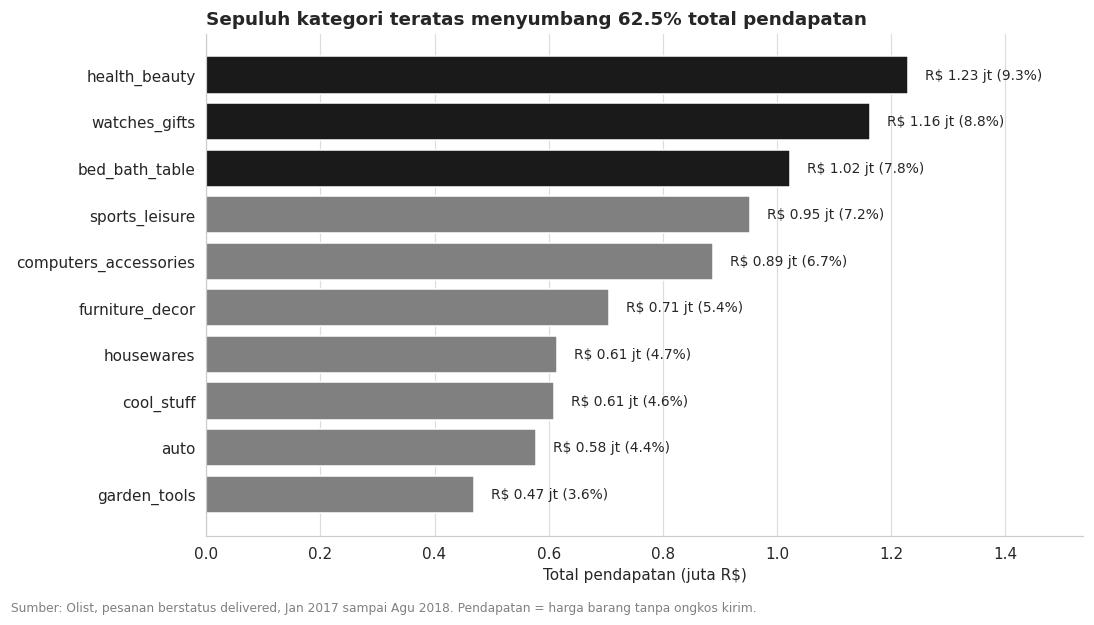

In [ ]:
# Top 10 kategori teratas penyumbang total pendapatan
top10 = category_rev.head(10).iloc[::-1]
colors = [DARK if i >= 7 else MID for i in range(10)]   # tiga kategori teratas diberi penekanan

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(top10["category_english"], top10["total_revenue"] / 1e6, color=colors)
for bar, rev, pct in zip(bars, top10["total_revenue"] / 1e6, top10["share_pct"]):
    ax.text(rev + 0.03, bar.get_y() + bar.get_height() / 2, f"R$ {rev:.2f} jt ({pct:.1f}%)", va="center", fontsize=9)

top10_share = category_rev["share_pct"].head(10).sum()
ax.set_title(f"Sepuluh kategori teratas menyumbang {top10_share:.1f}% total pendapatan", loc="left")
ax.set_xlabel("Total pendapatan (juta R$)")
ax.set_ylabel("")
ax.set_xlim(0, top10["total_revenue"].max() / 1e6 * 1.25)
ax.grid(axis="y", visible=False)
plt.figtext(0.01, -0.02, "Sumber: Olist, pesanan berstatus delivered, Jan 2017 sampai Agu 2018. Pendapatan = harga barang tanpa ongkos kirim.", fontsize=8, color=MID)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana tren jumlah pesanan dan pendapatan bulanan beserta pertumbuhan MoM?

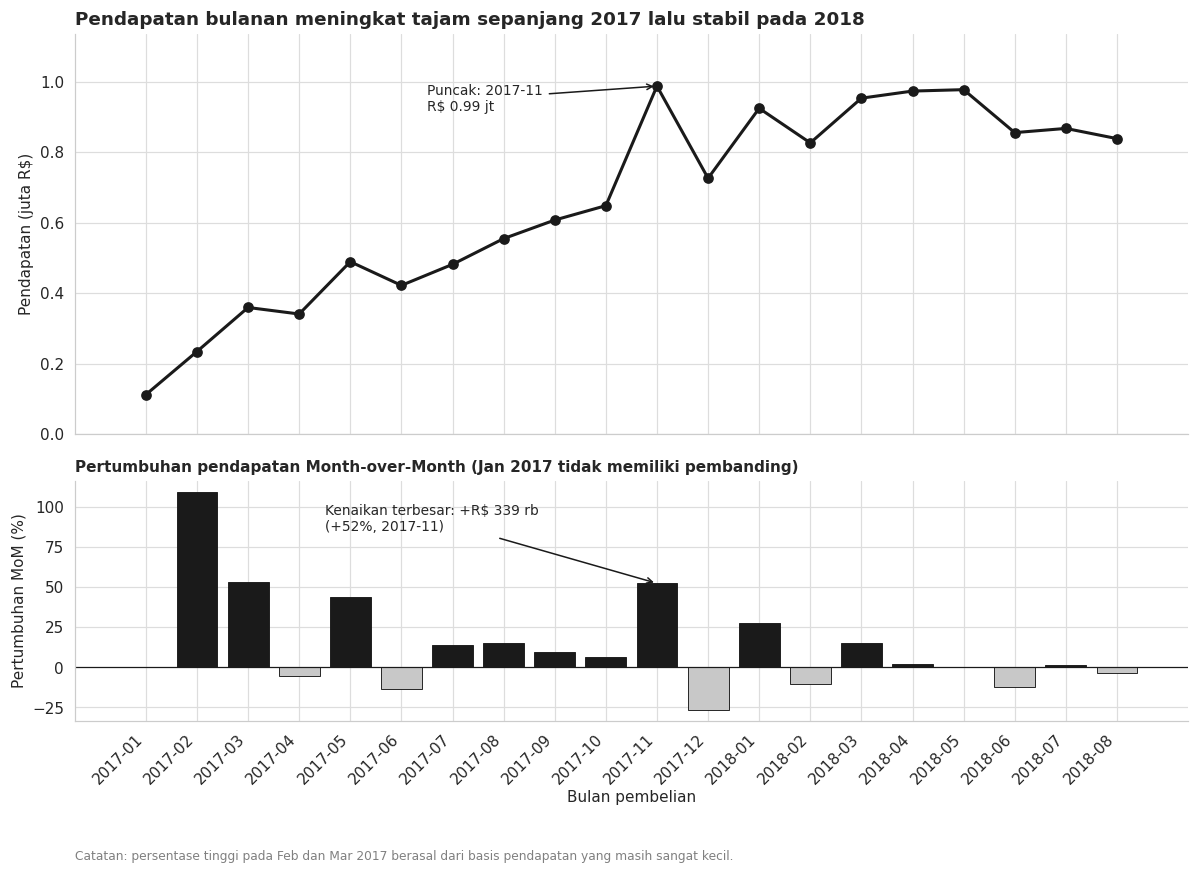

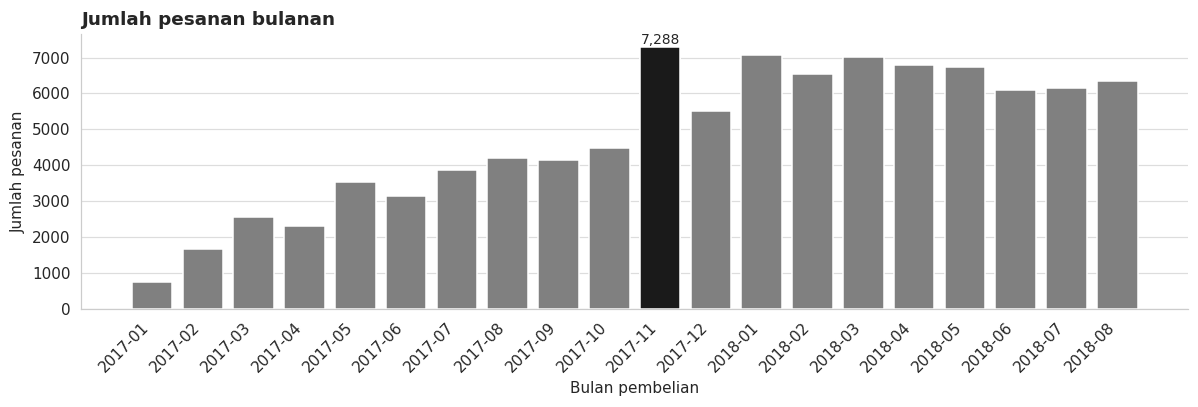

In [ ]:
m = monthly.copy()
m["label"] = m["purchase_month"].astype(str)

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1.2]})

# Panel atas: pendapatan bulanan
ax = axes[0]
ax.plot(m["label"], m["total_revenue"] / 1e6, color=DARK, marker="o", linewidth=2)
i_peak = m["total_revenue"].idxmax()
ax.annotate(f"Puncak: {m.loc[i_peak, 'label']}\nR$ {m.loc[i_peak, 'total_revenue'] / 1e6:.2f} jt",
            xy=(i_peak, m.loc[i_peak, "total_revenue"] / 1e6),
            xytext=(i_peak - 4.5, m.loc[i_peak, "total_revenue"] / 1e6 * 0.93),
            arrowprops=dict(arrowstyle="->", color=DARK), fontsize=9)
ax.set_title("Pendapatan bulanan meningkat tajam sepanjang 2017 lalu stabil pada 2018", loc="left")
ax.set_ylabel("Pendapatan (juta R$)")
ax.set_ylim(0, m["total_revenue"].max() / 1e6 * 1.15)

# Panel bawah: pertumbuhan MoM pendapatan
ax2 = axes[1]
mom = m["revenue_mom_pct"].fillna(0)
ax2.bar(m["label"], mom, color=[DARK if v >= 0 else LIGHT for v in mom], edgecolor=DARK, linewidth=0.6)
ax2.axhline(0, color=DARK, linewidth=0.8)
i_mom = m["revenue_mom_abs"].idxmax()   # kenaikan absolut terbesar
ax2.annotate(f"Kenaikan terbesar: +R$ {m.loc[i_mom, 'revenue_mom_abs'] / 1e3:.0f} rb\n(+{m.loc[i_mom, 'revenue_mom_pct']:.0f}%, {m.loc[i_mom, 'label']})",
             xy=(i_mom, m.loc[i_mom, "revenue_mom_pct"]),
             xytext=(i_mom - 6.5, 85), arrowprops=dict(arrowstyle="->", color=DARK), fontsize=9)
ax2.text(0.0, -0.58, "Catatan: persentase tinggi pada Feb dan Mar 2017 berasal dari basis pendapatan yang masih sangat kecil.",
         transform=ax2.transAxes, fontsize=8, color=MID)
ax2.set_ylabel("Pertumbuhan MoM (%)")
ax2.set_xlabel("Bulan pembelian", labelpad=2)
ax2.set_title("Pertumbuhan pendapatan Month-over-Month (Jan 2017 tidak memiliki pembanding)", loc="left", fontsize=10)
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Pelengkap: jumlah pesanan bulanan
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(m["label"], m["total_orders"], color=MID)
i_o = m["total_orders"].idxmax()
ax.bar(m.loc[i_o, "label"], m.loc[i_o, "total_orders"], color=DARK)
ax.text(i_o, m.loc[i_o, "total_orders"] + 100, f"{m.loc[i_o, 'total_orders']:,.0f}", ha="center", fontsize=9)
ax.set_title("Jumlah pesanan bulanan", loc="left")
ax.set_ylabel("Jumlah pesanan")
ax.set_xlabel("Bulan pembelian")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

### Pertanyaan 3: Seberapa besar dampak keterlambatan terhadap skor ulasan dan negara bagian mana yang paling sering terlambat?

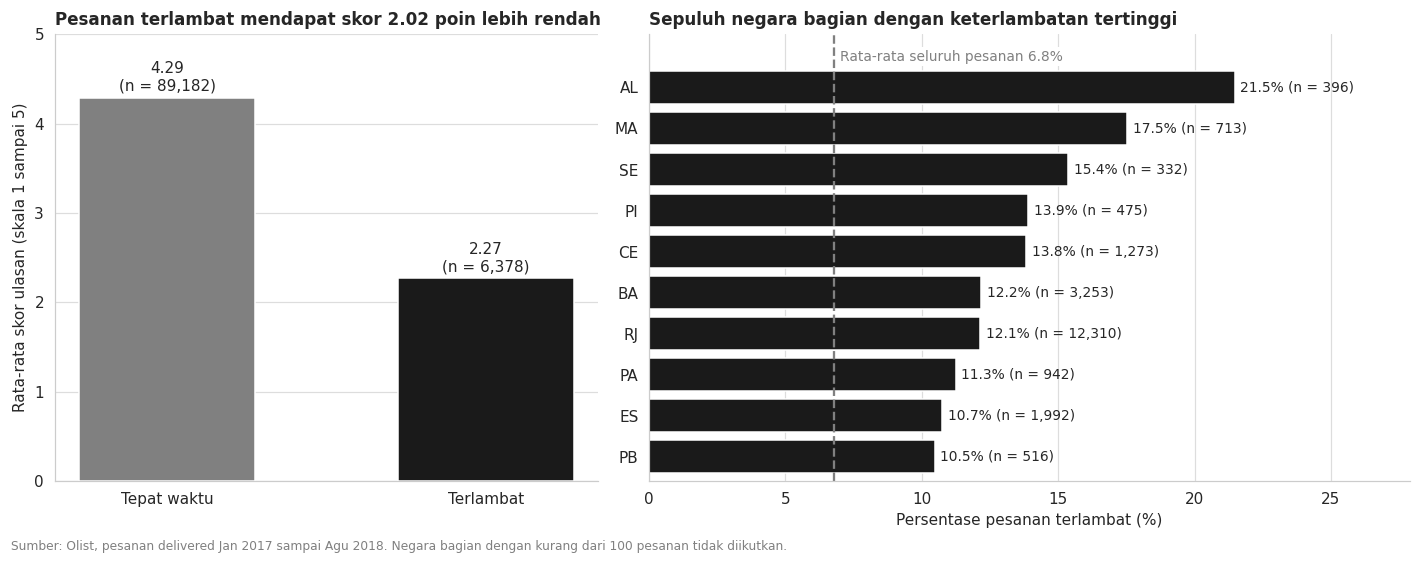

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.4]})

# Panel kiri: skor rata-rata tepat waktu vs terlambat
ax = axes[0]
vals = late_vs_ontime["rata2_skor"]
b = ax.bar(vals.index, vals.values, color=[MID, DARK], width=0.55)
for bar, v, n in zip(b, vals.values, late_vs_ontime["jumlah_pesanan"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.08, f"{v:.2f}\n(n = {n:,.0f})", ha="center", fontsize=10)
ax.set_ylim(0, 5)
ax.set_ylabel("Rata-rata skor ulasan (skala 1 sampai 5)")
ax.set_title(f"Pesanan terlambat mendapat skor {gap:.2f} poin lebih rendah", loc="left", fontsize=11)
ax.grid(axis="x", visible=False)

# Panel kanan: 10 negara bagian dengan keterlambatan tertinggi
ax = axes[1]
top_state = state_late.head(10).iloc[::-1]
ax.barh(top_state["customer_state"], top_state["late_rate_pct"], color=DARK)
ax.axvline(overall_late_rate, color=MID, linestyle="--", linewidth=1.5)
ax.text(overall_late_rate + 0.2, 9.75, f"Rata-rata seluruh pesanan {overall_late_rate:.1f}%", color=MID, fontsize=9, va="center",
        bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=5)
for y, (v, n) in enumerate(zip(top_state["late_rate_pct"], top_state["total_orders"])):
    ax.text(v + 0.2, y, f"{v:.1f}% (n = {n:,.0f})", va="center", fontsize=9)
ax.set_xlim(0, top_state["late_rate_pct"].max() * 1.3)
ax.set_ylim(-0.6, 10.3)
ax.set_xlabel("Persentase pesanan terlambat (%)")
ax.set_title("Sepuluh negara bagian dengan keterlambatan tertinggi", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)

plt.figtext(0.01, -0.01, "Sumber: Olist, pesanan delivered Jan 2017 sampai Agu 2018. Negara bagian dengan kurang dari 100 pesanan tidak diikutkan.", fontsize=8, color=MID)
plt.tight_layout()
plt.show()

**Insight:**
- **Pertanyaan 1:** tiga kategori teratas (`health_beauty`, `watches_gifts`, `bed_bath_table`) menyumbang sekitar 25,9% pendapatan, dan sepuluh kategori teratas menyumbang 62,5%. Tidak ada satu kategori pun yang melebihi 10%, sehingga pendapatan tersebar cukup merata dan tidak bergantung pada satu kategori. Sisa 64 kategori menyumbang 37,5%.
- **Pertanyaan 2:** pendapatan bulanan naik dari R\$ 111,8 ribu (Januari 2017) menjadi R\$ 987,6 ribu (November 2017), atau sekitar 8,8 kali lipat. Kenaikan terbesar terjadi pada November 2017 (+R\$ 339,4 ribu atau +52,4% MoM). Lonjakan ini diduga berkaitan dengan periode Black Friday, namun data tidak memuat informasi kampanye sehingga dugaan ini perlu dibuktikan lebih lanjut. Setelah itu pendapatan turun 26,5% pada Desember 2017 dan sepanjang 2018 bergerak mendatar pada kisaran R$ 0,83 sampai 0,98 juta per bulan, dengan perubahan MoM yang umumnya di bawah 16% (kecuali Januari 2018 yang naik 27,4%).
- **Pertanyaan 3:** pesanan terlambat mendapat skor rata-rata 2,27 dibandingkan 4,29 pada pesanan tepat waktu (selisih 2,02 poin). Pesanan terlambat hanya 6,7% dari seluruh ulasan, tetapi menyumbang 32,6% dari semua ulasan berskor 1 atau 2 (3.981 dari 12.228); sisanya 67,4% berasal dari pesanan tepat waktu, sehingga keterlambatan bukan satu-satunya penyebab ulasan buruk. Tiga negara bagian dengan persentase keterlambatan tertinggi (AL, MA, SE) seluruhnya berada di wilayah Timur Laut Brasil. Negara bagian RJ memiliki persentase keterlambatan 12,14% dan volume pesanan terbesar di antara negara bagian dengan keterlambatan di atas rata-rata (12.310 pesanan, 1.495 di antaranya terlambat), sehingga jumlah pesanan terlambatnya terbanyak kedua setelah SP (1.817). Temuan ini menunjukkan hubungan, bukan bukti sebab akibat.

## Analisis Lanjutan (Opsional)

Tiga teknik analisis lanjutan diterapkan tanpa algoritma *machine learning*:
1. **RFM Analysis** untuk mengelompokkan pelanggan berdasarkan *Recency* (hari sejak pembelian terakhir), *Frequency* (jumlah pesanan), dan *Monetary* (total harga barang). Tujuannya menentukan segmen pelanggan yang layak dipertahankan atau diaktifkan kembali.
2. **Analisis geospasial** untuk melihat sebaran pesanan berdasarkan koordinat kode pos pelanggan. Tujuannya mengidentifikasi konsentrasi permintaan secara geografis.
3. **Binning (manual grouping)** untuk mengelompokkan besar keterlambatan ke dalam rentang hari. Tujuannya melihat pada rentang keterlambatan mana skor ulasan mulai turun tajam.

### RFM Analysis

Catatan metodologis:
- Nilai *Monetary* dihitung dari total harga barang (`price`, tanpa ongkos kirim) agar konsisten dengan definisi pendapatan pada Pertanyaan 1 dan 2.
- Pelanggan diidentifikasi dengan `customer_unique_id` (bukan `customer_id`, karena `customer_id` dibuat baru untuk setiap pesanan).
- Titik acuan *recency* adalah satu hari setelah pesanan terakhir pada data. Skor *Recency* dan *Monetary* dibentuk dengan kuintil (1 sampai 5).
- Skor *Frequency* tidak dapat dibuat dengan kuintil karena sebagian besar pelanggan hanya bertransaksi satu kali, sehingga digunakan pengelompokan manual: 1 pesanan = skor 1, 2 pesanan = skor 3, 3 pesanan atau lebih = skor 5.

**Dasar pemilihan metode pengelompokan pelanggan**
- **Skor kuintil untuk Recency dan Monetary (1 sampai 5):** membagi pelanggan ke dalam lima kelompok berukuran sama berdasarkan peringkat, sehingga skor tidak terpengaruh nilai ekstrem.
- **Skor Frequency dikelompokkan manual (1, 3, dan 5):** hanya sekitar 3,0% dari 93.096 pelanggan yang bertransaksi lebih dari satu kali, sehingga kuintil tidak dapat dibentuk.
- **Tidak memakai satu skor gabungan berbobot:** pada distribusi *Frequency* yang sangat timpang, skor gabungan menjadikan *Frequency* hampir variabel biner sehingga label segmen kurang selaras dengan nilai pelanggan.
- **Aturan segmentasi disusun berurutan:** pelanggan berulang diidentifikasi lebih dahulu, kemudian pembeli satu kali dikelompokkan menurut *Recency* dan *Monetary* agar setiap segmen mudah dijelaskan secara bisnis.
- **Ambang skor (misalnya skor 4 ke atas) adalah keputusan analis:** tidak ada standar baku RFM, sehingga ambang dapat disesuaikan dengan kebutuhan bisnis.

In [ ]:
# Titik acuan recency: satu hari setelah pesanan terakhir pada data (bukan tanggal hari ini),
# sehingga pelanggan yang berbelanja pada hari terakhir memiliki recency 1.
snapshot_date = order_master["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
# Monetary: total harga barang per pesanan (tanpa ongkos kirim), konsisten dengan Pertanyaan 1 dan 2
price_per_order = item_master.groupby("order_id")["price"].sum().rename("order_value").reset_index()

# inner aman di sini karena seluruh pesanan memiliki setidaknya satu item
rfm_base = (order_master[["order_id", "customer_unique_id", "order_purchase_timestamp"]]
            .merge(price_per_order, on="order_id", how="inner"))

# Satu baris per pelanggan. frequency menghitung pesanan unik (bukan jumlah item).
rfm = (rfm_base.groupby("customer_unique_id")
       .agg(last_purchase=("order_purchase_timestamp", "max"),
            frequency=("order_id", "nunique"),
            monetary=("order_value", "sum")).reset_index())
rfm["recency"] = (snapshot_date - rfm["last_purchase"]).dt.days

# Skor kuintil (1 sampai 5). rank(method="first") memecah nilai kembar berdasarkan urutan baris,
# karena qcut langsung akan gagal akibat batas kuintil yang sama. Konsekuensinya, pelanggan dengan nilai
# identik di batas kuintil dapat memperoleh skor berbeda.
# Label recency dibalik: recency kecil (baru berbelanja) mendapat skor tertinggi.
rfm["r_score"] = pd.qcut(rfm["recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["m_score"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
# Frequency dikelompokkan manual (interval tertutup di kanan): 1 pesanan = skor 1, 2 pesanan atau lebih = skor 2
rfm["f_score"] = pd.cut(rfm["frequency"], bins=[0, 1, np.inf], labels=[1, 2]).astype(int)

# np.select mengambil kondisi PERTAMA yang terpenuhi, sehingga urutan daftar menentukan hasil.
# Pelanggan berulang (f_score >= 2) diambil lebih dulu, maka kondisi berikutnya hanya berlaku bagi pembeli satu kali.
# Ambang skor (misalnya 4) adalah keputusan analis, bukan standar baku RFM.
conditions = [
    (rfm["f_score"] >= 2) & (rfm["r_score"] >= 3),     # berulang dan masih cukup baru
    (rfm["f_score"] >= 2) & (rfm["r_score"] < 3),      # berulang tetapi sudah lama tidak berbelanja
    (rfm["r_score"] >= 4) & (rfm["m_score"] >= 4),     # pembeli satu kali, baru, nilai belanja tinggi
    (rfm["r_score"] >= 4),                             # pembeli satu kali, baru, nilai belanja rendah sampai menengah
    (rfm["r_score"] <= 3) & (rfm["m_score"] >= 4),     # pembeli satu kali, tidak baru, nilai belanja tinggi
]
labels = ["Pelanggan berulang aktif", "Pelanggan berulang tidak aktif", "Baru bernilai tinggi",
          "Baru bernilai rendah-menengah", "Berisiko bernilai tinggi"]
# default menampung sisanya: pembeli satu kali, tidak baru, nilai belanja rendah sampai menengah
rfm["segment"] = np.select(conditions, labels, default="Tidak aktif")

print("Jumlah pelanggan unik:", len(rfm))
print("Persentase pelanggan dengan lebih dari 1 pesanan:", round((rfm["frequency"] > 1).mean() * 100, 2), "%")
display(rfm[["recency", "frequency", "monetary"]].describe())

# Membandingkan porsi pelanggan dan porsi nilai belanja untuk melihat segmen kecil tetapi berkontribusi besar
seg = (rfm.groupby("segment")
       .agg(jumlah_pelanggan=("customer_unique_id", "count"),
            rata2_recency=("recency", "mean"), rata2_monetary=("monetary", "mean"),
            total_monetary=("monetary", "sum")).reset_index())
seg["pct_pelanggan"] = seg["jumlah_pelanggan"] / seg["jumlah_pelanggan"].sum() * 100
seg["pct_monetary"] = seg["total_monetary"] / seg["total_monetary"].sum() * 100
seg = seg.sort_values("pct_monetary", ascending=False).reset_index(drop=True)
seg

Jumlah pelanggan unik: 93096
Persentase pelanggan dengan lebih dari 1 pesanan: 3.0 %


,recency,frequency,monetary
count,"93,096.00","93,096.00","93,096.00"
mean,236.71,1.03,141.57
std,150.94,0.21,215.77
min,1.00,1.00,0.85
25%,114.00,1.00,47.65
50%,218.00,1.00,89.70
75%,345.00,1.00,154.16
max,602.00,15.00,"13,440.00"


,segment,jumlah_pelanggan,rata2_recency,rata2_monetary,total_monetary,pct_pelanggan,pct_monetary
0,Berisiko bernilai tinggi,20672,333.96,267.43,"5,528,349.07",22.21,41.95
1,Baru bernilai tinggi,14441,91.43,267.15,"3,857,906.19",15.51,29.27
2,Tidak aktif,33592,335.49,55.63,"1,868,822.29",36.08,14.18
3,Baru bernilai rendah-menengah,21602,89.38,55.52,"1,199,345.36",23.20,9.10
4,Pelanggan berulang aktif,1796,131.06,265.85,"477,461.60",1.93,3.62
5,Pelanggan berulang tidak aktif,993,379.74,249.64,"247,893.44",1.07,1.88


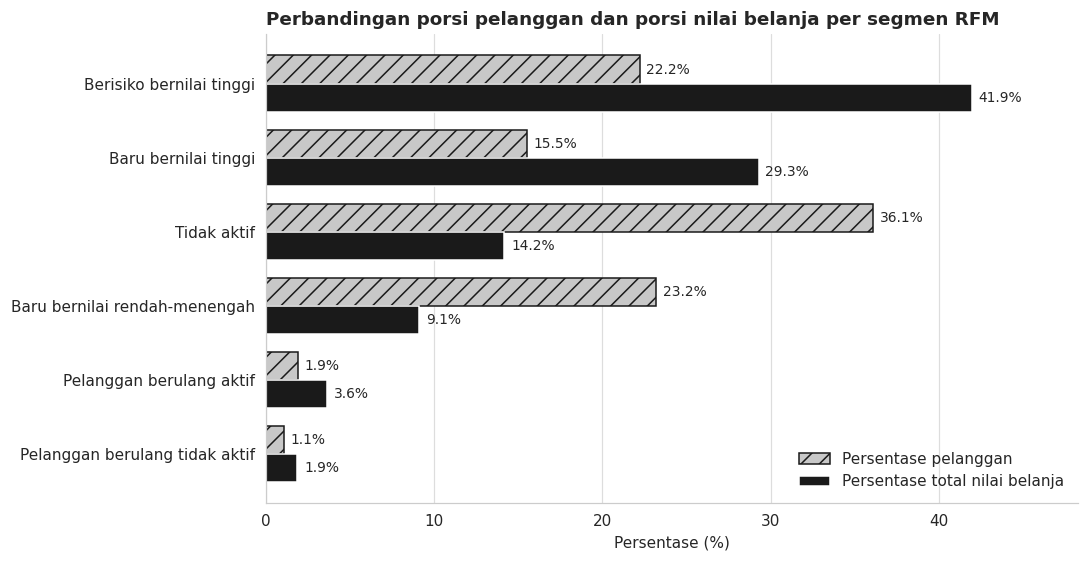

In [ ]:
# Segmentasi pelanggan berdasarkan RFM(Recency, Frequency, Monetary)
plot_seg = seg.iloc[::-1]
y = np.arange(len(plot_seg))
h = 0.38

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(y + h / 2, plot_seg["pct_pelanggan"], height=h, color=LIGHT, edgecolor=DARK, hatch="//", label="Persentase pelanggan")
ax.barh(y - h / 2, plot_seg["pct_monetary"], height=h, color=DARK, label="Persentase total nilai belanja")
for yi, a, b in zip(y, plot_seg["pct_pelanggan"], plot_seg["pct_monetary"]):
    ax.text(a + 0.4, yi + h / 2, f"{a:.1f}%", va="center", fontsize=9)
    ax.text(b + 0.4, yi - h / 2, f"{b:.1f}%", va="center", fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels(plot_seg["segment"])
ax.set_xlabel("Persentase (%)")
ax.set_title("Perbandingan porsi pelanggan dan porsi nilai belanja per segmen RFM", loc="left")
ax.set_xlim(0, max(plot_seg["pct_pelanggan"].max(), plot_seg["pct_monetary"].max()) * 1.15)
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Insight:**
- Hanya 3,0% pelanggan yang bertransaksi lebih dari satu kali. Dua segmen pelanggan berulang (2.789 pelanggan) hanya menyumbang 5,50% total nilai belanja, sehingga tingkat retensi tergolong sangat rendah.
- Segmen **berisiko bernilai tinggi** (20.672 pelanggan, 22,21% dari seluruh pelanggan) menyumbang 41,95% total nilai belanja dengan rata-rata R\$ 267,43 per pelanggan, tetapi rata-rata sudah 334,0 hari tidak berbelanja.
- Segmen **baru bernilai tinggi** (15,51% pelanggan) menyumbang 29,27% nilai belanja dengan rata-rata recency 91,4 hari. Pelanggan ini masih dapat didorong untuk membeli kembali.
- Segmen **tidak aktif** merupakan kelompok terbesar (36,08% pelanggan) tetapi hanya menyumbang 14,18% nilai belanja.
- Total nilai belanja seluruh pelanggan (R$ 13,18 juta) sama dengan total pendapatan pada Pertanyaan 1 dan 2, sehingga seluruh analisis memakai definisi yang konsisten.

### Analisis Geospasial

Cakupan pesanan yang dapat dipetakan: 99.72%


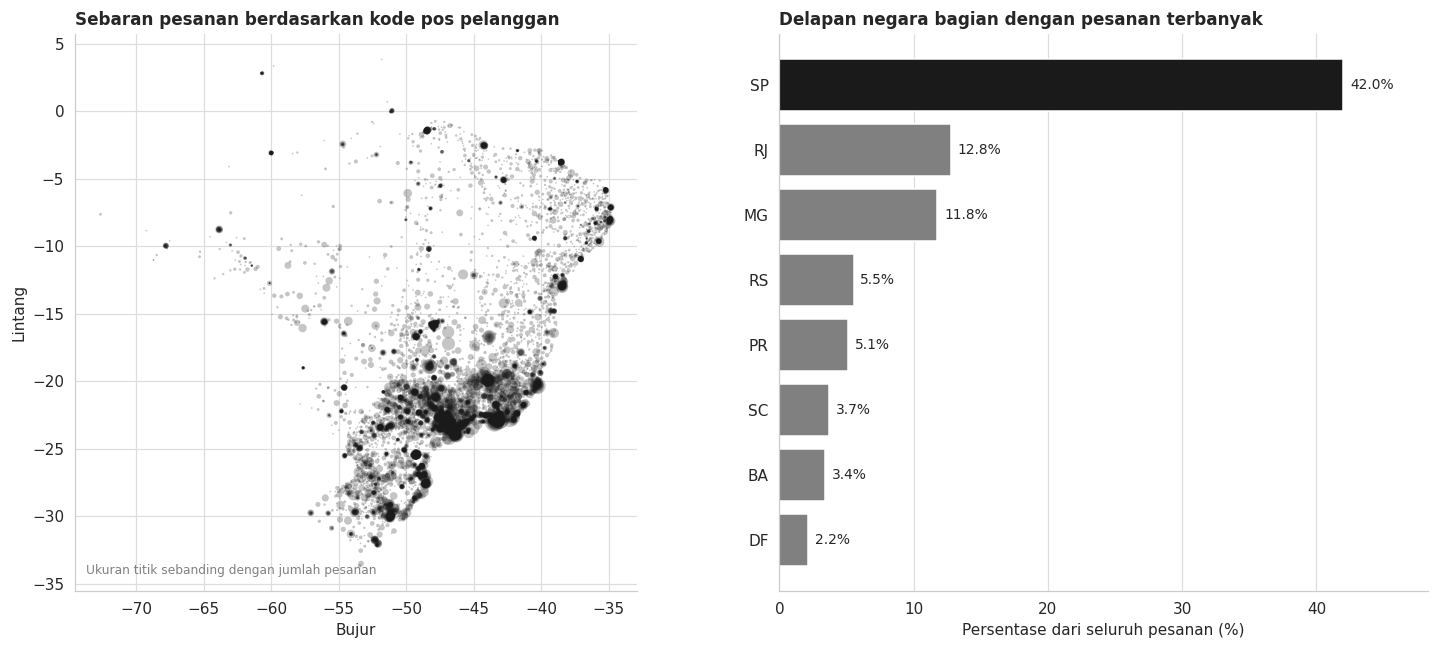

Kontribusi tiga negara bagian teratas: 66.56 %


,customer_state,total_orders,share_pct
25,SP,40399,41.99
18,RJ,12310,12.80
10,MG,11319,11.77
22,RS,5327,5.54
17,PR,4903,5.10


In [ ]:
geo_orders = (order_master.groupby("customer_zip_code_prefix")
              .agg(total_orders=("order_id", "count")).reset_index()
              .merge(geo_zip, left_on="customer_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="inner"))
coverage = geo_orders["total_orders"].sum() / len(order_master) * 100
print(f"Cakupan pesanan yang dapat dipetakan: {coverage:.2f}%")

state_orders = (order_master.groupby("customer_state")
                .agg(total_orders=("order_id", "count")).reset_index()
                .sort_values("total_orders", ascending=False))
state_orders["share_pct"] = state_orders["total_orders"] / state_orders["total_orders"].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.3, 1]})

# Panel kiri: Geografi sebaran pemesanan berdasarkan kode pos pelanggan
ax = axes[0]
ax.scatter(geo_orders["lng"], geo_orders["lat"], s=geo_orders["total_orders"] * 1.2,
           color=DARK, alpha=0.25, edgecolor="none")
ax.set_title("Sebaran pesanan berdasarkan kode pos pelanggan", loc="left", fontsize=11)
ax.set_xlabel("Bujur")
ax.set_ylabel("Lintang")
ax.set_aspect("equal")
ax.text(0.02, 0.03, "Ukuran titik sebanding dengan jumlah pesanan", transform=ax.transAxes, fontsize=8, color=MID)

# Panel kanan: Top 8 negara dengan pemesanan terbanyak
ax = axes[1]
top_s = state_orders.head(8).iloc[::-1]
ax.barh(top_s["customer_state"], top_s["share_pct"], color=[DARK if v >= top_s["share_pct"].max() else MID for v in top_s["share_pct"]])
for yi, v in enumerate(top_s["share_pct"]):
    ax.text(v + 0.5, yi, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("Persentase dari seluruh pesanan (%)")
ax.set_title("Delapan negara bagian dengan pesanan terbanyak", loc="left", fontsize=11)
ax.set_xlim(0, top_s["share_pct"].max() * 1.15)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print("Kontribusi tiga negara bagian teratas:", round(state_orders["share_pct"].head(3).sum(), 2), "%")
state_orders.head(5)

**Insight:**
- Sebanyak 99,72% pesanan dapat dipetakan berdasarkan kode pos pelanggan.
- Permintaan terkonsentrasi di wilayah Tenggara dan Selatan Brasil, terutama di sepanjang pesisir. Tiga negara bagian teratas (SP 41,99%, RJ 12,80%, MG 11,77%) menyumbang 66,56% seluruh pesanan.
- Wilayah Utara dan Timur Laut memiliki titik yang jauh lebih jarang, sejalan dengan temuan Pertanyaan 3 bahwa wilayah tersebut mengalami keterlambatan lebih tinggi.

### Binning: Besar Keterlambatan dan Skor Ulasan

,delay_bin,jumlah_pesanan,rata2_skor,pct_skor_1_2
0,Tepat waktu atau lebih cepat,89182,4.29,9.25
1,Terlambat 1 sampai 3 hari,1851,3.29,32.14
2,Terlambat 4 sampai 7 hari,1748,2.10,67.68
3,Terlambat 8 sampai 14 hari,1446,1.67,80.15
4,Terlambat lebih dari 14 hari,1333,1.72,78.32


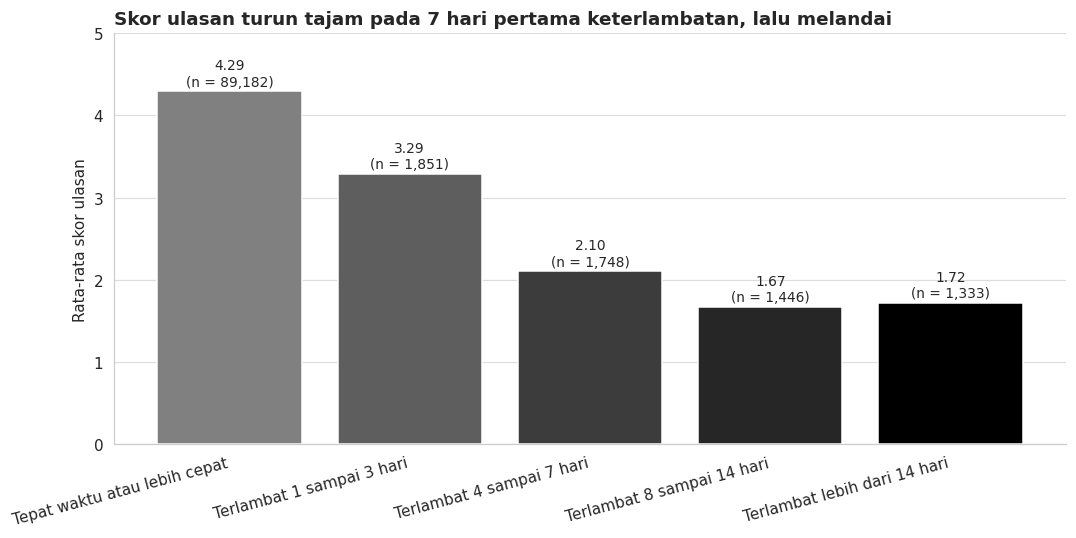

In [ ]:
# Hubungan nilai keterlambatan terhadap skor ulasan
bins = [-np.inf, 0, 3, 7, 14, np.inf]
bin_labels = ["Tepat waktu atau lebih cepat", "Terlambat 1 sampai 3 hari", "Terlambat 4 sampai 7 hari",
              "Terlambat 8 sampai 14 hari", "Terlambat lebih dari 14 hari"]
rev_valid = order_master.dropna(subset=["review_score"]).copy()
rev_valid["delay_bin"] = pd.cut(rev_valid["delay_days"], bins=bins, labels=bin_labels)

delay_bin = (rev_valid.groupby("delay_bin")
             .agg(jumlah_pesanan=("order_id", "count"), rata2_skor=("review_score", "mean"),
                  pct_skor_1_2=("review_score", lambda s: (s <= 2).mean() * 100)).reset_index())
display(delay_bin)

fig, ax = plt.subplots(figsize=(10, 5))
shades = [MID, "#5E5E5E", "#3C3C3C", "#262626", "#000000"]
b = ax.bar(delay_bin["delay_bin"], delay_bin["rata2_skor"], color=shades)
for bar, v, n in zip(b, delay_bin["rata2_skor"], delay_bin["jumlah_pesanan"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.07, f"{v:.2f}\n(n = {n:,.0f})", ha="center", fontsize=9)
ax.set_ylim(0, 5)
ax.set_ylabel("Rata-rata skor ulasan")
ax.set_title("Skor ulasan turun tajam pada 7 hari pertama keterlambatan, lalu melandai", loc="left")
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Insight:**
- Skor ulasan turun tajam sejak hari pertama keterlambatan: dari 4,29 (tepat waktu) menjadi 3,29 pada keterlambatan 1 sampai 3 hari, dan 2,10 pada keterlambatan 4 sampai 7 hari.
- Persentase ulasan berskor 1 atau 2 meningkat dari 9,25% (tepat waktu) menjadi 32,14% (1 sampai 3 hari) dan 67,68% (4 sampai 7 hari). Penurunan antar rentang terbesar terjadi antara rentang 1 sampai 3 hari dan 4 sampai 7 hari (1,19 poin).
- Setelah keterlambatan lebih dari 7 hari, skor mendatar pada kisaran 1,7 (80,15% dan 78,32% ulasan berskor 1 atau 2), sehingga penundaan tambahan tidak lagi menurunkan skor secara berarti.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Kategori dengan pendapatan tertinggi adalah `health_beauty` (R\$ 1.229.557,50 atau 9,33%), `watches_gifts` (8,83%), dan `bed_bath_table` (7,76%). Sepuluh kategori teratas menyumbang 62,47% total pendapatan pesanan *delivered* selama Januari 2017 sampai Agustus 2018, dengan pendapatan yang tersebar cukup merata (tidak ada kategori di atas 10%).
- **Conclusion pertanyaan 2:** Pendapatan bulanan tumbuh sekitar 8,8 kali lipat dari Januari sampai November 2017 dan mencapai puncak R$ 987.648 pada November 2017, yang juga merupakan kenaikan absolut terbesar (+R\$ 339.400 atau +52,4% MoM). Sepanjang 2018 pendapatan cenderung mendatar pada kisaran R\$ 0,83 sampai 0,98 juta per bulan, sehingga pertumbuhan telah melambat.
- **Conclusion pertanyaan 3:** Pesanan terlambat memperoleh skor ulasan rata-rata 2,27 dibandingkan 4,29 pada pesanan tepat waktu (selisih 2,02 poin). Persentase keterlambatan tertinggi terdapat di AL (21,46%), MA (17,53%), dan SE (15,36%), seluruhnya di wilayah Timur Laut, dibandingkan rata-rata keseluruhan 6,79%. Skor sudah turun menjadi 3,29 pada keterlambatan 1 sampai 3 hari dan menjadi 2,10 pada keterlambatan 4 sampai 7 hari.
- **Conclusion analisis lanjutan:** Hanya 3,0% pelanggan yang berbelanja ulang, sedangkan segmen pelanggan berisiko bernilai tinggi menyumbang 41,95% total nilai belanja. Permintaan terkonsentrasi di SP, RJ, dan MG (66,56% pesanan).

**Rekomendasi Action Item:**
- **Prioritas kategori:** fokuskan stok, promosi, dan akuisisi penjual pada sepuluh kategori teratas, terutama `health_beauty`, `watches_gifts`, dan `bed_bath_table`. Pantau pula kategori di luar sepuluh besar karena menyumbang 37,5% pendapatan.
- **Kalender kampanye dan kapasitas:** siapkan stok, kapasitas gudang, dan layanan pelanggan menjelang November (periode puncak), serta rancang kampanye pada Desember dan pertengahan 2018 untuk mengurangi penurunan pendapatan dan menggerakkan kembali pertumbuhan yang mendatar.
- **Perbaikan logistik wilayah Timur Laut:** prioritaskan AL, MA, dan SE (keterlambatan 15% sampai 21%) melalui evaluasi mitra kurir, penyesuaian estimasi tiba yang lebih realistis, serta notifikasi proaktif ketika keterlambatan diperkirakan terjadi. Pesanan yang terlambat lebih dari 3 hari sebaiknya ditangani lebih dulu karena skor turun hingga di bawah 2,1. Untuk RJ, fokus pada pengurangan jumlah pesanan terlambat karena volumenya besar.
- **Retensi pelanggan:** lakukan kampanye reaktivasi (misalnya voucher atau surel personal) untuk 20.672 pelanggan segmen berisiko bernilai tinggi dan dorong pembelian kedua pada pelanggan baru bernilai tinggi. Tujuannya meningkatkan tingkat pembelian ulang yang baru 3,0%.
- **Analisis lanjutan yang disarankan:** uji hubungan antara kategori produk, penjual, dan keterlambatan, serta validasi dugaan efek Black Friday menggunakan data kampanye.